# 第 0 课：从波到频谱

## 学完你能做什么

- 用“配方表”解释频谱，而不是死背公式；
- 看懂频率、振幅、相位；
- 用 `np.fft.fft` 找出一维信号中隐藏的周期。

> 两小时原则：先运行、拖动参数、观察，再读解释。暂时不用推导积分公式。


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["image.cmap"] = "gray"
plt.rcParams["axes.grid"] = True
# 优先使用常见中文字体；最后的 DejaVu Sans 保证数字和英文正常显示
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def show_images(images, titles, cmap="gray"):
    """并排显示若干幅图像。"""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4))
    axes = np.atleast_1d(axes)
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap=cmap)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


## 0. 傅里叶变换需要的数学：一圈、正弦与弧度

高中三角函数常用角度，但 Python 的 `sin` 使用**弧度**：

- 走完一整圈：360° = $2\pi$ 弧度；
- 半圈：180° = $\pi$ 弧度；
- 四分之一圈：90° = $\pi/2$ 弧度。

想象一个点沿圆周匀速旋转。这个点的纵坐标随时间变化，画出来就是正弦波。正弦波不是凭空出现的公式，它是“匀速转圈在竖直方向上的投影”。


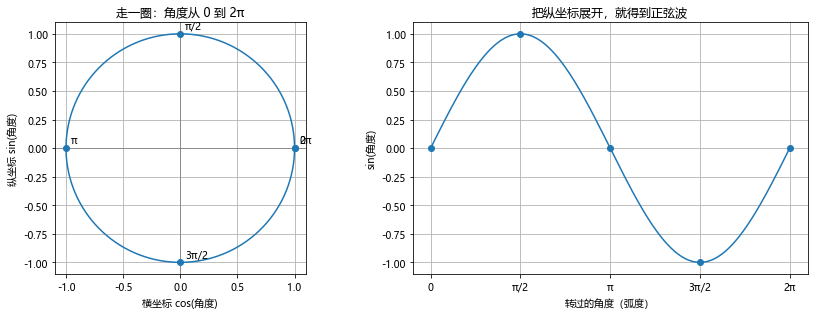

In [2]:
angles = np.linspace(0, 2*np.pi, 400)
selected = np.array([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 左：圆周运动
axes[0].plot(np.cos(angles), np.sin(angles))
axes[0].scatter(np.cos(selected), np.sin(selected), zorder=3)
for a, label in zip(selected, ["0", "π/2", "π", "3π/2", "2π"]):
    axes[0].annotate(label, (np.cos(a), np.sin(a)), xytext=(5, 5), textcoords="offset points")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].axvline(0, color="gray", linewidth=0.8)
axes[0].set_aspect("equal")
axes[0].set_title("走一圈：角度从 0 到 2π")
axes[0].set_xlabel("横坐标 cos(角度)")
axes[0].set_ylabel("纵坐标 sin(角度)")

# 右：圆上点的纵坐标展开成波
axes[1].plot(angles, np.sin(angles))
axes[1].scatter(selected, np.sin(selected), zorder=3)
axes[1].set_xticks(selected)
axes[1].set_xticklabels(["0", "π/2", "π", "3π/2", "2π"])
axes[1].set_title("把纵坐标展开，就得到正弦波")
axes[1].set_xlabel("转过的角度（弧度）")
axes[1].set_ylabel("sin(角度)")
plt.tight_layout(); plt.show()


## 0.1 看懂工程里常见的正弦公式

$$y(t)=A\sin(2\pi f t+\varphi)$$

不需要推导，只要读懂每个零件：

- $t$：时间；
- $A$：振幅，控制上下摆动有多高；
- $f$：频率，控制每秒转几圈，单位 Hz；
- $2\pi ft$：经过 $t$ 秒一共转了多少弧度；
- $\varphi$（读作 phi）：相位，表示出发前已经提前转了多少角度。

`2 * np.pi * f * t` 就是公式 $2\pi ft$ 的 Python 写法。


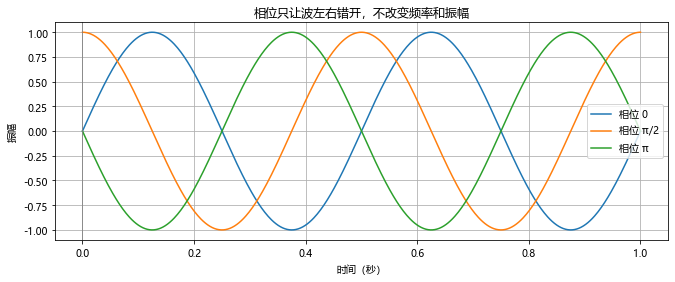

In [3]:
t_demo = np.linspace(0, 1, 500)
f_demo = 2

plt.figure(figsize=(11, 4))
for phase, label in [(0, "相位 0"), (np.pi/2, "相位 π/2"), (np.pi, "相位 π")]:
    plt.plot(t_demo, np.sin(2*np.pi*f_demo*t_demo + phase), label=label)
plt.axvline(0, color="gray", linewidth=0.8)
plt.xlabel("时间（秒）")
plt.ylabel("振幅")
plt.title("相位只让波左右错开，不改变频率和振幅")
plt.legend(); plt.show()


上图三条波每秒都重复 2 次，振幅也都是 1，区别只是从周期中的不同位置出发。因此：

> **相位描述同一种周期变化在什么位置。** 对图像而言，它对边缘和物体出现在什么位置非常重要。


## 0.2 从直角坐标系到“换一套坐标轴”

先不谈傅里叶。平面上的同一个箭头，可以用不同坐标系描述：

- 在普通直角坐标系中，它由“水平方向多少、竖直方向多少”描述；
- 把坐标轴旋转后，箭头没有变化，但两个坐标值变了。

所以**换坐标系不是改变对象，而是改用另一套基本方向描述同一个对象**。


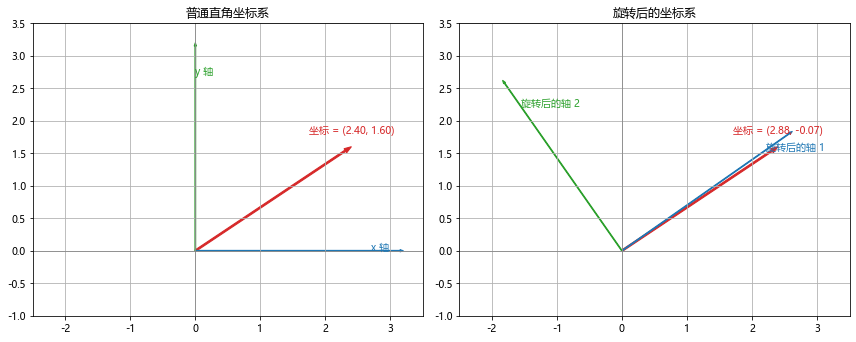

In [4]:
v = np.array([2.4, 1.6])
theta = np.deg2rad(35)
e1 = np.array([np.cos(theta), np.sin(theta)])
e2 = np.array([-np.sin(theta), np.cos(theta)])
new_coordinates = np.array([v @ e1, v @ e2])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

def draw_vector_and_basis(ax, basis1, basis2, labels, coordinates, title):
    ax.arrow(0, 0, v[0], v[1], width=0.025, length_includes_head=True,
             color="tab:red", label="同一个箭头 v")
    scale = 3.2
    ax.arrow(0, 0, *(scale*basis1), width=0.012, length_includes_head=True,
             color="tab:blue")
    ax.arrow(0, 0, *(scale*basis2), width=0.012, length_includes_head=True,
             color="tab:green")
    ax.text(*(2.7*basis1), labels[0], color="tab:blue")
    ax.text(*(2.7*basis2), labels[1], color="tab:green")
    ax.text(v[0], v[1]+0.2, f"坐标 = ({coordinates[0]:.2f}, {coordinates[1]:.2f})",
            ha="center", color="tab:red")
    ax.set_xlim(-2.5, 3.5); ax.set_ylim(-1.0, 3.5)
    ax.set_aspect("equal"); ax.set_title(title)
    ax.axhline(0, color="gray", linewidth=0.7); ax.axvline(0, color="gray", linewidth=0.7)
    ax.grid(True)

draw_vector_and_basis(axes[0], np.array([1,0]), np.array([0,1]),
                      ["x 轴", "y 轴"], v, "普通直角坐标系")
draw_vector_and_basis(axes[1], e1, e2,
                      ["旋转后的轴 1", "旋转后的轴 2"], new_coordinates, "旋转后的坐标系")
plt.tight_layout(); plt.show()


傅里叶变换做的是同一类事情，只是对象从二维箭头换成了一整段信号：

- 普通描述：第 0 个时刻是多少、第 1 个时刻是多少……这些采样值就是原坐标；
- 傅里叶描述：0 Hz 波有多少、1 Hz 波有多少、2 Hz 波有多少……这些波的含量就是新坐标。

二维空间只有两根坐标轴；含有 $N$ 个采样点的信号可以看作一个 $N$ 维向量。人无法画出 $N$ 维空间，但“换一组基本方向”的原理完全相同。

> 普通坐标轴关注每个位置；傅里叶坐标轴是一组不同频率的正弦波和余弦波。


## 1. 正弦波是频域的基本积木

正弦波可以理解为一种永不改变节奏的振动：

- **频率**：每秒重复几次，单位 Hz；
- **振幅**：波有多强；
- **相位**：波从周期中的哪个位置开始。

下面把 3 Hz 和 8 Hz 的波相加。观察混合信号很复杂，但它的“配方”只有两项。


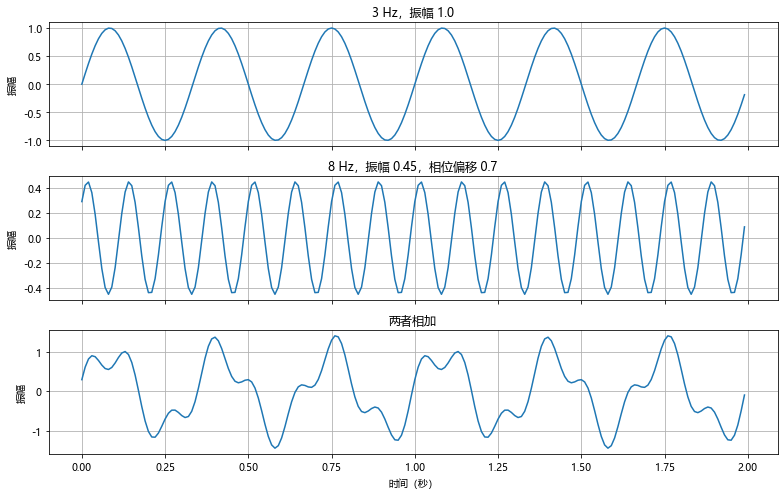

In [5]:
sample_rate = 100       # 每秒采 100 个点
duration = 2            # 共观察 2 秒
t = np.arange(0, duration, 1 / sample_rate)

wave_3hz = 1.0 * np.sin(2 * np.pi * 3 * t)
wave_8hz = 0.45 * np.sin(2 * np.pi * 8 * t + 0.7)
mixed = wave_3hz + wave_8hz

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, y, title in zip(axes, [wave_3hz, wave_8hz, mixed],
                        ["3 Hz，振幅 1.0", "8 Hz，振幅 0.45，相位偏移 0.7", "两者相加"]):
    ax.plot(t, y)
    ax.set_title(title)
    ax.set_ylabel("振幅")
axes[-1].set_xlabel("时间（秒）")
plt.tight_layout()
plt.show()


## 1.1 怎样测量信号在某根“频率坐标轴”上有多少？

在直角坐标系里，我们把箭头投影到 x 轴、y 轴来得到坐标。傅里叶变换也做投影：依次拿不同频率的波与原信号比较。

- 节奏匹配时，同向部分会不断累加，得到较大的坐标；
- 节奏不匹配时，正负部分互相抵消，坐标接近零。

下面暂时不用 `fft`，而是手动让 0～15 Hz 的“探测波”逐一试探。正弦和余弦都要测，是为了不被相位错开影响。


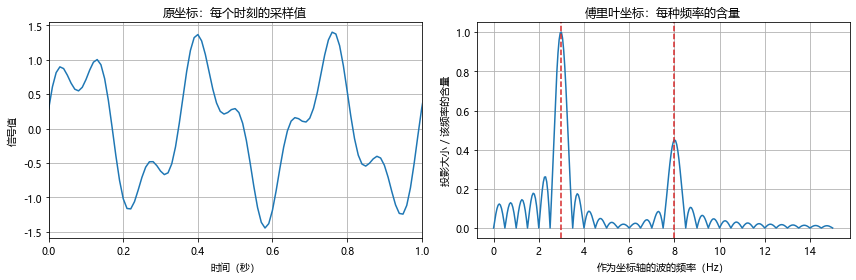

In [6]:
candidate_freqs = np.linspace(0, 15, 301)
coordinates = []

for f in candidate_freqs:
    cosine_axis = np.cos(2*np.pi*f*t)
    sine_axis = np.sin(2*np.pi*f*t)
    coordinate_cos = 2/len(t) * np.sum(mixed * cosine_axis)
    coordinate_sin = 2/len(t) * np.sum(mixed * sine_axis)
    coordinates.append(np.sqrt(coordinate_cos**2 + coordinate_sin**2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(t, mixed)
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("时间（秒）"); axes[0].set_ylabel("信号值")
axes[0].set_title("原坐标：每个时刻的采样值")

axes[1].plot(candidate_freqs, coordinates)
axes[1].set_xlabel("作为坐标轴的波的频率（Hz）")
axes[1].set_ylabel("投影大小 / 该频率的含量")
axes[1].set_title("傅里叶坐标：每种频率的含量")
axes[1].axvline(3, color="tab:red", linestyle="--")
axes[1].axvline(8, color="tab:red", linestyle="--")
plt.tight_layout(); plt.show()


右图在 3 Hz 和 8 Hz 出现峰，因为原信号正是由这两个频率组成。这幅图就是傅里叶变换最核心的直觉：

> **不是把波形神奇地“变成”频谱，而是在一组波形坐标轴上重新读取同一个信号的坐标。**

手动试探很慢；FFT 是一种高效算法，可以一次算出所有这些坐标。


## 2. 傅里叶变换在回答什么？

时域问：“每个时刻的值是多少？” 频域问：“这个信号由哪些频率组成，各有多强？”

`fft` 产生复数。现阶段记住：

- `abs(FFT)` 给出强度（幅度谱）；
- `angle(FFT)` 给出相位；
- 实信号的负频率部分与正频率镜像，所以工程中常看 `rfft`。


### 先把 FFT 函数当作工程工具使用

```python
F = np.fft.rfft(signal)                     # 输入一维实数信号，得到频率成分
freqs = np.fft.rfftfreq(len(signal), 1/fs)  # 为每个频率成分生成 Hz 坐标
amplitude = np.abs(F)                       # 取每个频率成分的强度
signal_back = np.fft.irfft(F)               # 从频域还原为信号
```

`F` 不是一张可以直接看的图，而是一组复数。画频谱时，横坐标用 `freqs`，纵坐标通常用 `np.abs(F)`。


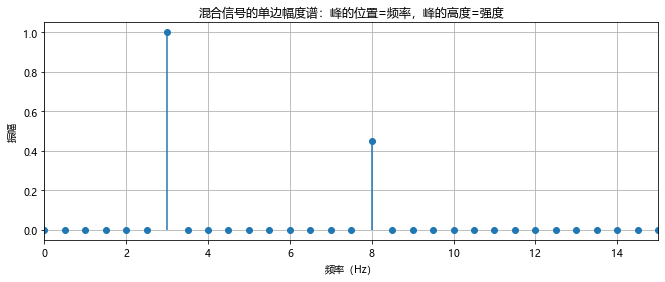

In [7]:
F = np.fft.rfft(mixed)
freqs = np.fft.rfftfreq(len(mixed), d=1 / sample_rate)

# 除以样本数并乘 2，把柱高换算回正弦波振幅（直流项除外）
amplitude = 2 * np.abs(F) / len(mixed)
amplitude[0] /= 2

plt.figure(figsize=(11, 4))
plt.stem(freqs, amplitude, basefmt=" ")
plt.xlim(0, 15)
plt.xlabel("频率（Hz）")
plt.ylabel("振幅")
plt.title("混合信号的单边幅度谱：峰的位置=频率，峰的高度=强度")
plt.show()


## 2.1 为什么 FFT 会产生复数？

一个实数只能记录一条数轴上的位置；复数使用两个数 `(实部, 虚部)` 记录平面上的一个点。FFT 用这个平面点同时表达：

- 点离原点多远 → 该频率有多强，即**幅度**；
- 点朝哪个方向 → 该频率转到了周期中的什么位置，即**相位**。

工程中可以把复数理解为“同时装着幅度和相位的容器”。`abs(z)` 取距离，`angle(z)` 取方向。


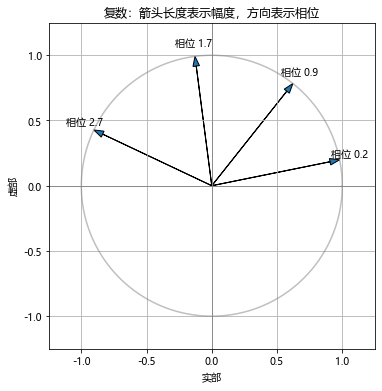

In [8]:
phases = np.array([0.2, 0.9, 1.7, 2.7])
amplitudes = np.array([1.0, 1.0, 1.0, 1.0])
z = amplitudes * np.exp(1j * phases)

fig, ax = plt.subplots(figsize=(6, 6))
circle = np.linspace(0, 2*np.pi, 300)
ax.plot(np.cos(circle), np.sin(circle), color="gray", alpha=0.5)
for point, phase in zip(z, phases):
    ax.arrow(0, 0, point.real, point.imag, head_width=0.05,
             length_includes_head=True)
    ax.text(point.real*1.08, point.imag*1.08, f"相位 {phase:.1f}", ha="center")
ax.axhline(0, color="gray", linewidth=0.8); ax.axvline(0, color="gray", linewidth=0.8)
ax.set_aspect("equal"); ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25)
ax.set_xlabel("实部"); ax.set_ylabel("虚部")
ax.set_title("复数：箭头长度表示幅度，方向表示相位")
plt.show()


上面的 `np.exp(1j * phases)` 暂时不要求会推导。它的作用只是：“根据给定相位，在复数平面上生成相应方向的箭头”。

## 2.2 负频率到底是什么？

正频率和负频率不是“频率小于零”或“时间倒流”，而是复数平面上的两个旋转方向：

- 正频率：一个方向旋转；
- 负频率：相反方向旋转。

真实的正弦或余弦信号可以看成两个相反方向的旋转合在一起，所以完整 FFT 会在 `+f` 和 `-f` 各出现一个对称峰。处理实数信号时，负频率通常没有新增信息，因此 `rfft` 只返回不重复的右半边。


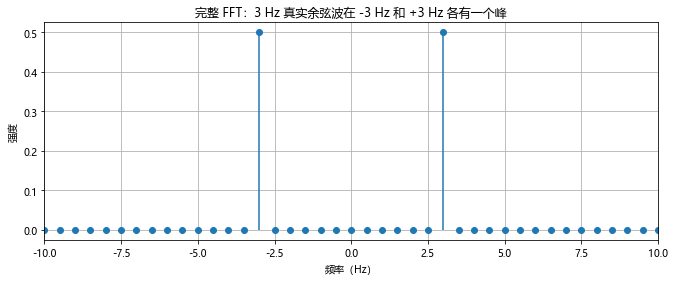

In [9]:
cosine = np.cos(2*np.pi*3*t)
F_full = np.fft.fftshift(np.fft.fft(cosine))
freq_full = np.fft.fftshift(np.fft.fftfreq(len(cosine), d=1/sample_rate))

plt.figure(figsize=(11, 4))
plt.stem(freq_full, np.abs(F_full)/len(cosine), basefmt=" ")
plt.xlim(-10, 10)
plt.xlabel("频率（Hz）")
plt.ylabel("强度")
plt.title("完整 FFT：3 Hz 真实余弦波在 -3 Hz 和 +3 Hz 各有一个峰")
plt.show()


### 你需要掌握到什么程度？

- 要会：实数信号的完整频谱左右对称，`rfft` 可以只看非负频率；
- 要会：复数的长度保存幅度，方向保存相位；
- 暂时不用：用欧拉公式推导正弦波为什么等于两个反向旋转。


### 现在请回答（先猜，再运行）

1. 哪两个频率峰最高？
2. 8 Hz 的峰为什么比 3 Hz 低？
3. 把 `wave_8hz` 的振幅从 `0.45` 改成 `1.5`，频谱如何变化？

答案：3 Hz 和 8 Hz；因为设定振幅较小；改振幅只改变对应峰高，不改变峰的位置。


## 3. 图像里的“频率”是什么？

图像没有时间轴，但有空间坐标。空间频率描述亮暗变化得多快：

- 平缓背景：低频；
- 细纹理、文字、边缘：高频；
- 水平方向快速明暗交替，会在频域水平方向出现离中心较远的能量。

下一课将把这套直觉扩展到二维。


## 本课最小记忆卡

`信号 --FFT--> 频谱`，`频谱 --逆 FFT--> 信号`

- 峰在哪里 → 有什么频率；
- 峰多高 → 该频率有多强；
- 高频不是“数值高”，而是“变化快”。
